# 🏠 House Price Prediction in Sukkur — A Complete Regression Project

**AI & Data Science Course · Module 5: Machine Learning · Lab 1 (Regression)**
Trainer: **Arslan Ahmed**

In the theory lecture we learned the **10 steps of an ML project**. Today we follow every step, in order, on one real-looking dataset.

| Step | What we do | Section |
|---|---|---|
| 1 | Define the problem | 1 |
| 2 | Collect (load) the data | 2 |
| 3 | Clean the data | 3 |
| 4 | Explore the data (EDA) | 4 |
| 5 | Prepare the features | 5 |
| 6 | Split the data | 6 |
| 7 | Choose and train models | 7 |
| 8 | Evaluate the models | 8 |
| 9 | Tune and improve | 9 |
| 10 | Save the model and predict (deploy) | 10 |

> **How to use this notebook:** run the cells one by one from top to bottom (**Shift + Enter**). Read the text before each cell. Questions marked **✏️ Your turn** are for you to try.

## Step 1 · Define the problem

**Question:** A property dealer in Sukkur wants to know: *"What is a fair price for this house?"*

- **Input (features, X):** location, area, bedrooms, bathrooms, floors, age, condition, garage, corner plot, near main road, year listed
- **Output (target, y):** `price_lakh` — the price in **lakh rupees** (1 lakh = 100,000 Rs)
- **Type of problem:** the answer is a **number**, so this is **supervised learning → regression**.
- **How we judge success:** MAE (average error in lakh), RMSE and R². A dealer will be happy if we are off by only a few lakh on average.

> ℹ️ The dataset is a **practice dataset made for this course**. The prices follow realistic patterns for Sukkur areas, and we added real-life problems on purpose (missing values, typing mistakes, duplicates) so you can practise cleaning.

### Import the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: the main ML library in Python
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42   # fixed number so everyone gets the same results

## Step 2 · Collect (load) the data
Keep `sukkur_house_prices.csv` in the **same folder** as this notebook.

In [2]:
df = pd.read_csv("sukkur_house_prices.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1215, 14)


,house_id,location,area_marla,bedrooms,bathrooms,floors,house_age,condition,garage,corner_plot,near_main_road,listed_year,price_lakh,price_per_marla
0,SKR-1446,Bunder Road,10.0,3,2.0,2,20.0,Poor,No,Yes,No,2025,148.7,14.87
1,SKR-1290,Old Sukkur,6.0,3,3.0,1,7.0,Good,No,No,Yes,2026,67.2,11.20
2,SKR-1569,Shikarpur Road,5.0,2,1.0,1,30.0,Average,No,Yes,No,2024,37.7,7.54
3,SKR-1180,Barrage Colony,3.0,1,1.0,2,7.0,Good,Yes,No,Yes,2026,67.0,22.33
4,SKR-2035,Old Sukkur,3.0,2,1.0,2,9.0,Average,No,No,No,2025,25.8,8.60


### What does each column mean?

| Column | Meaning |
|---|---|
| `house_id` | ID of the listing (just a name, not useful for learning) |
| `location` | Area of the city |
| `area_marla` | Size of the plot in marla |
| `bedrooms`, `bathrooms`, `floors` | Counts |
| `house_age` | Age of the house in years |
| `condition` | Poor < Average < Good < Excellent (has an order → **ordinal**) |
| `garage`, `corner_plot`, `near_main_road` | Yes / No |
| `listed_year` | Year the house was listed for sale |
| `price_lakh` | **Target** — selling price in lakh Rs |
| `price_per_marla` | Price ÷ area ⚠️ (we will talk about this one) |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   house_id         1215 non-null   str    
 1   location         1215 non-null   str    
 2   area_marla       1215 non-null   float64
 3   bedrooms         1215 non-null   int64  
 4   bathrooms        1179 non-null   float64
 5   floors           1215 non-null   int64  
 6   house_age        1162 non-null   float64
 7   condition        1189 non-null   str    
 8   garage           1215 non-null   str    
 9   corner_plot      1215 non-null   str    
 10  near_main_road   1215 non-null   str    
 11  listed_year      1215 non-null   int64  
 12  price_lakh       1215 non-null   float64
 13  price_per_marla  1215 non-null   float64
dtypes: float64(5), int64(3), str(6)
memory usage: 133.0 KB


In [4]:
df.describe()

,area_marla,bedrooms,bathrooms,floors,house_age,listed_year,price_lakh,price_per_marla
count,1215.000000,1215.000000,1179.000000,1215.000000,1162.000000,1215.000000,1215.000000,1215.000000
mean,9.999177,3.404115,2.924512,1.601646,13.207401,2024.981070,106.584774,13.714774
std,61.620317,1.440351,1.491994,0.605573,8.781343,0.776808,71.756319,4.275383
min,3.000000,1.000000,1.000000,1.000000,-3.000000,2024.000000,22.500000,4.940000
25%,5.000000,2.000000,2.000000,1.000000,6.000000,2024.000000,59.550000,10.230000
50%,7.000000,3.000000,3.000000,2.000000,11.000000,2025.000000,89.600000,13.040000
75%,10.000000,4.000000,4.000000,2.000000,18.000000,2026.000000,133.850000,16.640000
max,2000.000000,8.000000,8.000000,3.000000,45.000000,2026.000000,1109.000000,30.610000


**Look carefully at `describe()`:**
- `area_marla` has a **max of 1000+ marla**. That is not a house, that is a farm! Probably someone typed `500` instead of `5`.
- `house_age` has a **negative** minimum. A house cannot be −3 years old.
- `price_lakh` max is around **1,100 lakh** while 75% of houses are under ~135 lakh. Suspicious.

We fix these in Step 3.

## Step 3 · Clean the data
### 3.1 Remove duplicate rows

In [5]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 15
Shape after removing duplicates: (1200, 14)


### 3.2 Fix messy text in `location`

In [6]:
print("Before:", df["location"].nunique(), "different spellings")
print(df["location"].value_counts())

Before: 27 different spellings
location
Old Sukkur          195
Shikarpur Road      188
Military Road       185
Airport Road        162
Barrage Colony      159
Rohri               154
Bunder Road         121
Shikarpur Rd          4
military road         3
BUNDER ROAD           3
 Shikarpur Road       2
Airport Rd            2
 Old Sukkur           2
airport road          2
 Rohri                2
 Military Road        2
shikarpur road        2
BARRAGE COLONY        2
AIRPORT ROAD          2
 Airport Road         1
OLD SUKKUR            1
 Barrage Colony       1
bunder road           1
rohri                 1
SHIKARPUR ROAD        1
barrage colony        1
MILITARY ROAD         1
Name: count, dtype: int64


The same place is written in different ways (`military road`, ` Military Road `, `MILITARY ROAD`, `Military Rd`). The computer thinks these are different places. Let's fix them.

In [7]:
df["location"] = (df["location"]
                  .str.strip()                       # remove extra spaces
                  .str.title()                       # Military Road style
                  .str.replace(r"\bRd\b", "Road", regex=True))
print("After:", df["location"].nunique(), "locations")
df["location"].value_counts()

After: 7 locations


location
Old Sukkur        198
Shikarpur Road    197
Military Road     191
Airport Road      169
Barrage Colony    163
Rohri             157
Bunder Road       125
Name: count, dtype: int64

### 3.3 Impossible values

In [8]:
print("Houses with area over 50 marla:")
display(df[df["area_marla"] > 50][["house_id", "area_marla", "bedrooms", "price_lakh"]])

print("Houses with negative age:")
display(df[df["house_age"] < 0][["house_id", "house_age"]])

Houses with area over 50 marla:


,house_id,area_marla,bedrooms,price_lakh
367,SKR-1452,2000.0,7,346.1
1053,SKR-1911,800.0,4,126.8


Houses with negative age:


,house_id,house_age
665,SKR-1454,-3.0


- 500 marla with 2 bedrooms is a typing mistake. We cannot be 100% sure of the real value, so we **remove** these rows.
- A negative age is impossible. We set it to **missing (NaN)**. The pipeline will fill it later.

In [9]:
df = df[df["area_marla"] <= 50].copy()
df.loc[df["house_age"] < 0, "house_age"] = np.nan
print("Shape now:", df.shape)

Shape now: (1198, 14)


### 3.4 Price outliers
A good check: **price per marla**. In Sukkur it is normally a few lakh per marla. Let's look for strange values.

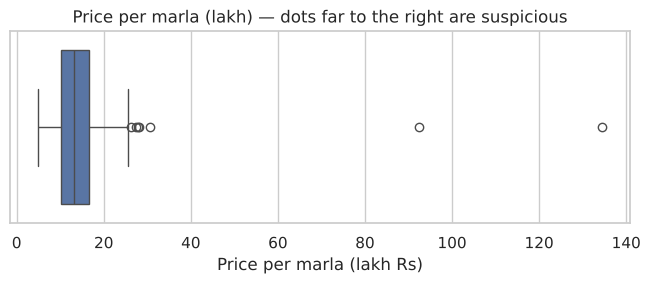

,house_id,location,area_marla,price_lakh
407,SKR-1735,Military Road,5.0,672.0
1057,SKR-1915,Airport Road,12.0,1109.0


In [10]:
check = df["price_lakh"] / df["area_marla"]       # only for checking, not a feature
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=check)
plt.title("Price per marla (lakh) — dots far to the right are suspicious")
plt.xlabel("Price per marla (lakh Rs)")
plt.show()

display(df[check > 40][["house_id", "location", "area_marla", "price_lakh"]])

These prices are about **10 times too high** — an extra zero was typed. We remove them.

In [11]:
df = df[check <= 40].copy()
print("Shape now:", df.shape)

Shape now: (1196, 14)


### 3.5 Drop columns that should not be used
- `house_id` is just a name. It has no pattern to learn.
- `price_per_marla` is made **from the price itself** (price ÷ area). If we give it to the model, the model can calculate the answer exactly. This is **data leakage** — remember "the exam paper leaked"? For a new house we will **not know** this value, because we do not know the price yet!

In [12]:
df = df.drop(columns=["house_id", "price_per_marla"])
df.head()

,location,area_marla,bedrooms,bathrooms,floors,house_age,condition,garage,corner_plot,near_main_road,listed_year,price_lakh
0,Bunder Road,10.0,3,2.0,2,20.0,Poor,No,Yes,No,2025,148.7
1,Old Sukkur,6.0,3,3.0,1,7.0,Good,No,No,Yes,2026,67.2
2,Shikarpur Road,5.0,2,1.0,1,30.0,Average,No,Yes,No,2024,37.7
3,Barrage Colony,3.0,1,1.0,2,7.0,Good,Yes,No,Yes,2026,67.0
4,Old Sukkur,3.0,2,1.0,2,9.0,Average,No,No,No,2025,25.8


### 3.6 Missing values — look, but do not fill yet!

In [13]:
df.isna().sum()

location           0
area_marla         0
bedrooms           0
bathrooms         35
floors             0
house_age         51
condition         25
garage             0
corner_plot        0
near_main_road     0
listed_year        0
price_lakh         0
dtype: int64

We have missing values in `bathrooms`, `house_age` and `condition`.

⚠️ **Golden rule from the lecture:** *split first, then learn the fill values from the training data only.*
So we will **not** fill them here. We will fill them inside a **Pipeline** in Step 5, which learns the median/most-common values from the training set only.

## Step 4 · Explore the data (EDA)
### 4.1 The target: how are prices spread?

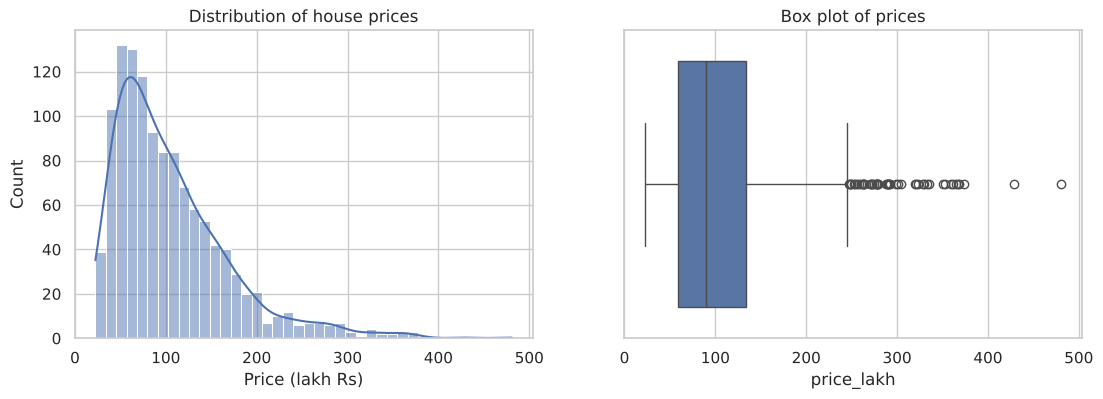

Average price: 105.2 lakh | Median: 89.4 lakh


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price_lakh"], bins=40, kde=True, ax=ax[0])
ax[0].set_title("Distribution of house prices")
ax[0].set_xlabel("Price (lakh Rs)")
sns.boxplot(x=df["price_lakh"], ax=ax[1])
ax[1].set_title("Box plot of prices")
plt.show()
print("Average price:", round(df["price_lakh"].mean(), 1), "lakh | Median:", df["price_lakh"].median(), "lakh")

Prices are **right-skewed**: most houses are cheaper, and a few big houses are very expensive. That is normal for house prices.

### 4.2 Area vs price — the strongest relationship

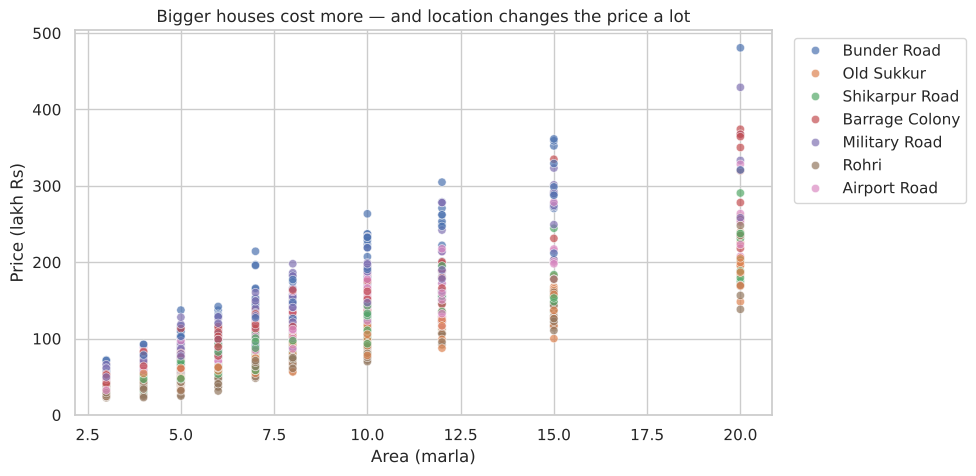

In [15]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="area_marla", y="price_lakh", hue="location", alpha=0.7)
plt.title("Bigger houses cost more — and location changes the price a lot")
plt.xlabel("Area (marla)"); plt.ylabel("Price (lakh Rs)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 4.3 Location and condition

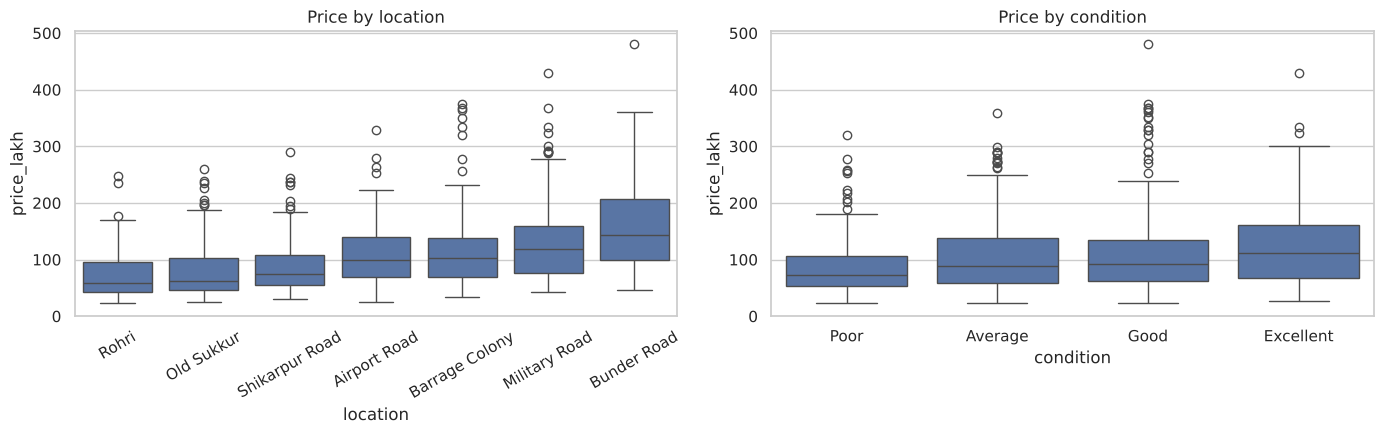

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order = df.groupby("location")["price_lakh"].median().sort_values().index
sns.boxplot(data=df, x="location", y="price_lakh", order=order, ax=ax[0])
ax[0].set_title("Price by location"); ax[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="condition", y="price_lakh", order=["Poor", "Average", "Good", "Excellent"], ax=ax[1])
ax[1].set_title("Price by condition")
plt.tight_layout(); plt.show()

### 4.4 Correlation between numeric columns

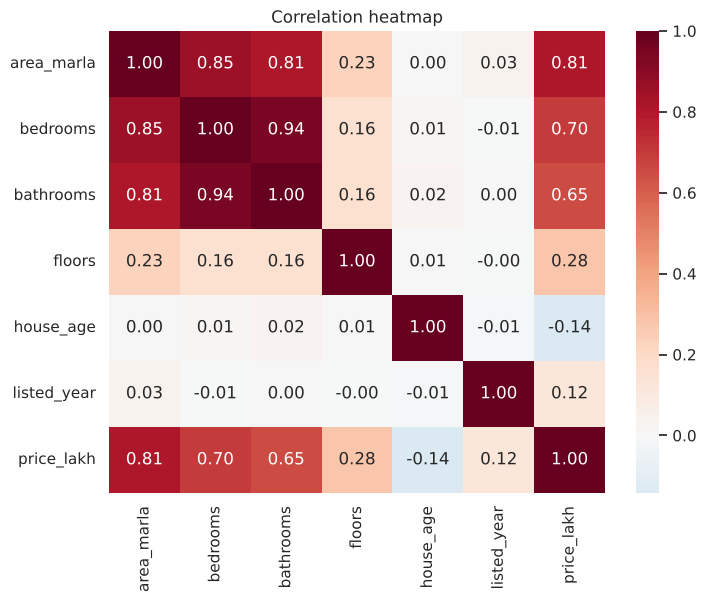

In [17]:
num_cols = ["area_marla", "bedrooms", "bathrooms", "floors", "house_age", "listed_year", "price_lakh"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation heatmap")
plt.show()

**What did we learn?**
1. `area_marla` has the strongest link with price.
2. `bedrooms` and `bathrooms` are also linked, but they are linked with area too (bigger house → more rooms).
3. **Location** matters a lot: Bunder Road and Military Road are expensive, Rohri and Old Sukkur are cheaper.
4. Better **condition** → higher price. Older houses are a little cheaper.

✏️ **Your turn:** make a box plot of `price_lakh` by `garage`. Do houses with a garage cost more?

## Step 5 · Prepare the features
The model only understands **numbers**. We prepare each type of column differently:

| Column type | Columns | What we do |
|---|---|---|
| Numeric | area, bedrooms, bathrooms, floors, house_age, listed_year | fill missing with **median** → **standardise** (z-score) |
| Nominal (no order) | location, garage, corner_plot, near_main_road | fill missing with most common → **one-hot encoding** |
| Ordinal (has order) | condition | fill missing with most common → **ordinal encoding** (Poor=0 … Excellent=3) |

We put all of this in a **ColumnTransformer** so it is applied the same way to training data, test data and new houses.

In [18]:
target = "price_lakh"
numeric_features = ["area_marla", "bedrooms", "bathrooms", "floors", "house_age", "listed_year"]
nominal_features = ["location", "garage", "corner_plot", "near_main_road"]
ordinal_features = ["condition"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
nominal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
ordinal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[["Poor", "Average", "Good", "Excellent"]])),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("nom", nominal_pipe, nominal_features),
    ("ord", ordinal_pipe, ordinal_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Step 6 · Split the data
We keep **20% of the houses hidden** as the **test set** (the final exam). We do not touch it until Step 8.
Instead of one fixed validation set, we will use **5-fold cross-validation** on the training set to compare models (Step 7).

In [19]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training houses:", X_train.shape[0])
print("Test houses    :", X_test.shape[0])

Training houses: 956
Test houses    : 240


## Step 7 · Choose and train models
### 7.1 Start simple: a straight line with only one feature
Remember the lecture: **price = w × area + b**. Let's see what *w* and *b* the model learns.

Learned line:  price = 12.94 × area + 4.98
Meaning: each extra marla adds about 12.9 lakh to the price.


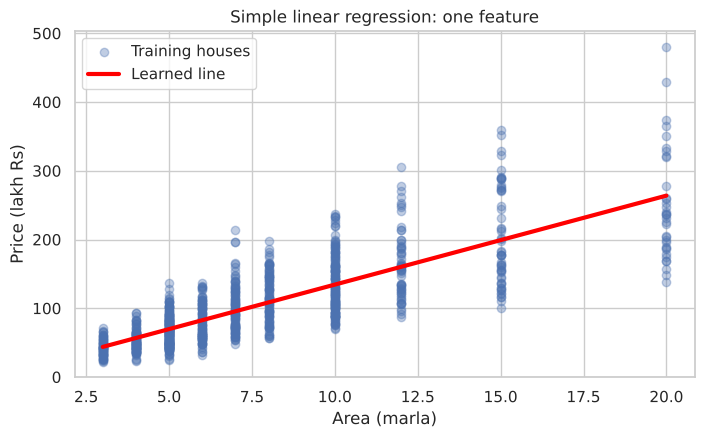

In [20]:
simple = LinearRegression()
simple.fit(X_train[["area_marla"]], y_train)

w, b = simple.coef_[0], simple.intercept_
print(f"Learned line:  price = {w:.2f} × area + {b:.2f}")
print(f"Meaning: each extra marla adds about {w:.1f} lakh to the price.")

xs = np.linspace(X_train["area_marla"].min(), X_train["area_marla"].max(), 50)
plt.figure(figsize=(8, 4.5))
plt.scatter(X_train["area_marla"], y_train, alpha=0.35, label="Training houses")
plt.plot(xs, w * xs + b, color="red", linewidth=3, label="Learned line")
plt.xlabel("Area (marla)"); plt.ylabel("Price (lakh Rs)"); plt.legend()
plt.title("Simple linear regression: one feature")
plt.show()

The line follows the general trend, but houses of the same size have very different prices (because of location, condition…). One feature is **not enough** — this model **underfits**. Let's use **all features** and try several algorithms.

### 7.2 Compare several models with cross-validation
Every model is put inside a Pipeline: **preprocessor → model**. Cross-validation repeats the preparation inside each fold, so there is **no leakage**.

We include a **baseline** (`DummyRegressor`) that always predicts the average price. Every real model must beat it!

In [21]:
models = {
    "Baseline (average)": DummyRegressor(strategy="mean"),
    "Linear Regression":  LinearRegression(),
    "Ridge (L2)":         Ridge(alpha=1.0),
    "Decision Tree":      DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest":      RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    rows.append({
        "Model": name,
        "CV MAE":   -res["test_MAE"].mean(),
        "CV RMSE":  -res["test_RMSE"].mean(),
        "CV R2":     res["test_R2"].mean(),
        "Train R2":  res["train_R2"].mean(),
    })

results = pd.DataFrame(rows).sort_values("CV MAE").reset_index(drop=True)
results.round(3)

,Model,CV MAE,CV RMSE,CV R2,Train R2
0,Gradient Boosting,9.882,15.608,0.938,0.980
1,Random Forest,11.054,17.412,0.923,0.989
2,Ridge (L2),13.280,19.390,0.905,0.910
3,Linear Regression,13.340,19.396,0.905,0.910
4,Decision Tree,17.167,27.192,0.812,1.000
5,Baseline (average),47.583,63.088,-0.006,0.000


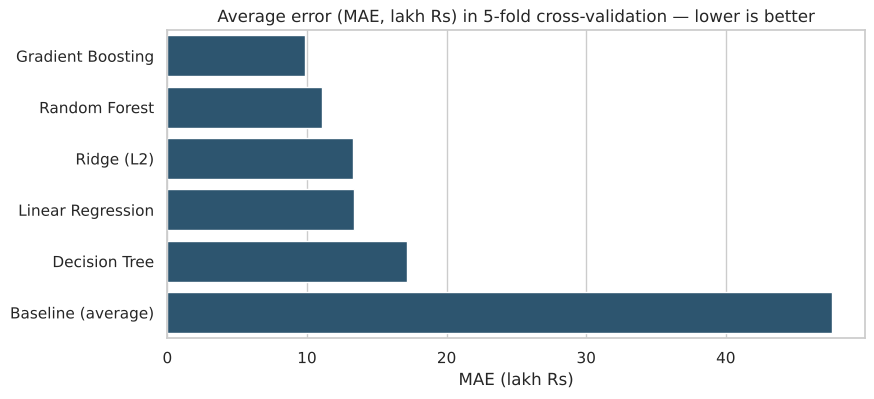

In [22]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results, y="Model", x="CV MAE", color="#22577A")
plt.title("Average error (MAE, lakh Rs) in 5-fold cross-validation — lower is better")
plt.xlabel("MAE (lakh Rs)"); plt.ylabel("")
plt.show()

**How to read the table:**
- **CV MAE** — on average, how many lakh the model is wrong on houses it did **not** train on.
- **Train R2 vs CV R2** — if Train R² is much higher than CV R², the model is **overfitting**. Look at the **Decision Tree**: Train R² = 1.00 (perfect memory!) but its CV score is lower. It memorised the training houses.
- The **baseline** shows how bad "just guess the average" is. All real models beat it by far.

✏️ **Your turn:** which model has the lowest CV MAE? Is it the most complex one?

## Step 8 · Evaluate on the test set
We pick the best model from cross-validation and train it on the **full training set**. Then we test it **once** on the hidden test set.

In [23]:
best_name = results.loc[0, "Model"]
print("Best model in cross-validation:", best_name)

best_pipe = Pipeline([("prep", preprocessor), ("model", models[best_name])])
best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

def report(y_true, y_hat, label):
    mae  = mean_absolute_error(y_true, y_hat)
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    r2   = r2_score(y_true, y_hat)
    print(f"{label}:  MAE = {mae:.2f} lakh | RMSE = {rmse:.2f} lakh | R² = {r2:.3f}")
    return mae, rmse, r2

_ = report(y_test, y_pred, best_name + " (test set)")

Best model in cross-validation: Gradient Boosting
Gradient Boosting (test set):  MAE = 10.39 lakh | RMSE = 15.81 lakh | R² = 0.942


### 8.1 Actual vs predicted

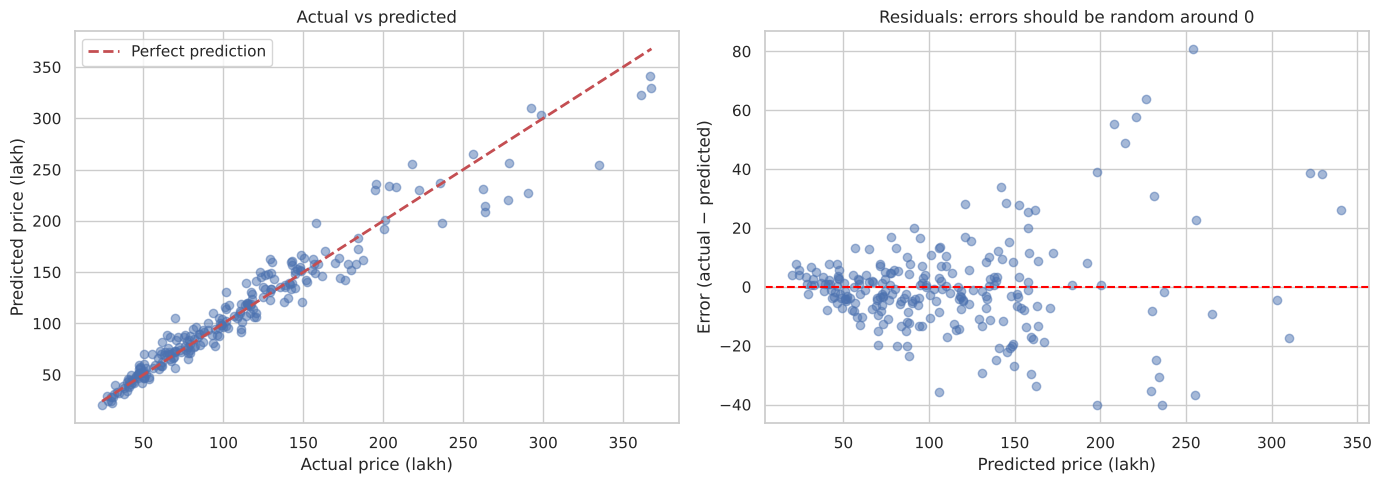

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", linewidth=2, label="Perfect prediction")
ax[0].set_xlabel("Actual price (lakh)"); ax[0].set_ylabel("Predicted price (lakh)")
ax[0].set_title("Actual vs predicted"); ax[0].legend()

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.5)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Predicted price (lakh)"); ax[1].set_ylabel("Error (actual − predicted)")
ax[1].set_title("Residuals: errors should be random around 0")
plt.tight_layout(); plt.show()

- **Left:** points close to the red line = good predictions.
- **Right:** errors should look like a random cloud around 0. If errors grow for expensive houses, the model is less sure about big houses (common in price data).

### 8.2 Look at a few predictions

In [25]:
sample = X_test.copy()
sample["actual_price"] = y_test.values
sample["predicted_price"] = y_pred.round(1)
sample["error"] = (sample["actual_price"] - sample["predicted_price"]).round(1)
sample[["location", "area_marla", "bedrooms", "condition", "actual_price", "predicted_price", "error"]].head(10)

,location,area_marla,bedrooms,condition,actual_price,predicted_price,error
638,Military Road,6.0,2,Excellent,118.2,113.6,4.6
243,Airport Road,20.0,8,Poor,207.8,232.6,-24.8
1015,Old Sukkur,10.0,5,Average,98.5,98.5,0.0
1117,Military Road,7.0,2,Good,115.2,118.3,-3.1
58,Military Road,6.0,2,Good,111.9,101.2,10.7
1024,Shikarpur Road,5.0,3,Excellent,66.6,65.1,1.5
708,Shikarpur Road,5.0,2,Average,45.1,48.9,-3.8
628,Barrage Colony,8.0,4,Good,138.4,137.8,0.6
107,Barrage Colony,4.0,2,Excellent,67.7,71.1,-3.4
584,Airport Road,5.0,3,Good,78.1,71.1,7.0


## Step 9 · Tune and improve
### 9.1 Hyperparameter tuning with GridSearchCV
Gradient Boosting won Step 7. Now we try different **settings** (hyperparameters) for it and keep the best, using cross-validation on the **training set only**.

- `n_estimators` — how many small trees are added one after another
- `learning_rate` — how big each correction step is (remember the learning rate lecture!)
- `max_depth` — how deep each small tree can grow
- `subsample` — each tree learns from a random part of the rows (helps against overfitting)

In [26]:
gb_pipe = Pipeline([("prep", preprocessor),
                    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])

param_grid = {
    "model__n_estimators":  [200, 400],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth":     [2, 3, 4],
    "model__subsample":     [0.8, 1.0],
}
grid = GridSearchCV(gb_pipe, param_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(X_train, y_train)

print("Combinations tried:", len(grid.cv_results_["params"]))
print("Best settings:", grid.best_params_)
print(f"Best CV MAE: {-grid.best_score_:.2f} lakh")

Combinations tried: 24
Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 400, 'model__subsample': 0.8}
Best CV MAE: 8.47 lakh


In [27]:
tuned_pred = grid.best_estimator_.predict(X_test)
_ = report(y_test, y_pred, "Untuned Gradient Boosting")
_ = report(y_test, tuned_pred, "Tuned Gradient Boosting")

Untuned Gradient Boosting:  MAE = 10.39 lakh | RMSE = 15.81 lakh | R² = 0.942
Tuned Gradient Boosting:  MAE = 8.74 lakh | RMSE = 13.05 lakh | R² = 0.960


### 9.2 Which features matter most?

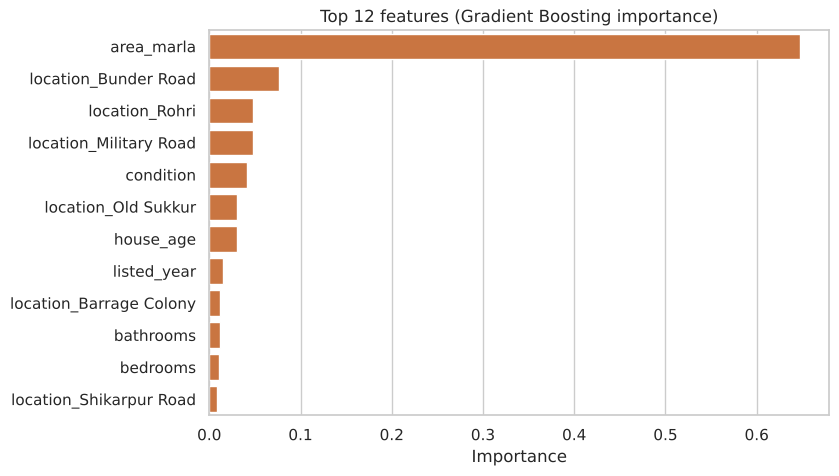

In [28]:
gb = grid.best_estimator_.named_steps["model"]
names = grid.best_estimator_.named_steps["prep"].get_feature_names_out()
imp = (pd.Series(gb.feature_importances_, index=names)
         .sort_values(ascending=False).head(12))
imp.index = imp.index.str.replace("num__|nom__|ord__", "", regex=True)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#E0702A")
plt.title("Top 12 features (Gradient Boosting importance)")
plt.xlabel("Importance"); plt.ylabel("")
plt.show()

As expected from EDA, **area** is the most important feature, followed by **location** and other details.

### 9.3 Choose the final model
We compare the untuned and the tuned model using **cross-validation scores** (not the test set!), and keep the better one.

In [29]:
best_cv_mae  = results.loc[0, "CV MAE"]
tuned_cv_mae = -grid.best_score_

if tuned_cv_mae < best_cv_mae:
    final_model, final_name = grid.best_estimator_, "Tuned Gradient Boosting"
else:
    final_model, final_name = best_pipe, best_name

print("Final model:", final_name)
final_mae, final_rmse, final_r2 = report(y_test, final_model.predict(X_test), "Final model on test set")

Final model: Tuned Gradient Boosting
Final model on test set:  MAE = 8.74 lakh | RMSE = 13.05 lakh | R² = 0.960


## Step 10 · Save the model and use it (deploy)
The saved file contains the **whole pipeline** (cleaning of missing values, scaling, encoding **and** the model). So a new house can be given exactly as raw data.

In [30]:
joblib.dump(final_model, "house_price_model.joblib")
print("Saved: house_price_model.joblib")

Saved: house_price_model.joblib


### 10.1 Load the model and predict the price of a new house

In [31]:
loaded_model = joblib.load("house_price_model.joblib")

new_houses = pd.DataFrame([
    {"location": "Military Road", "area_marla": 8, "bedrooms": 4, "bathrooms": 3, "floors": 2,
     "house_age": 4, "condition": "Good", "garage": "Yes", "corner_plot": "No",
     "near_main_road": "Yes", "listed_year": 2026},
    {"location": "Rohri", "area_marla": 5, "bedrooms": 3, "bathrooms": 2, "floors": 1,
     "house_age": 18, "condition": "Average", "garage": "No", "corner_plot": "No",
     "near_main_road": "No", "listed_year": 2026},
])

new_houses["predicted_price_lakh"] = loaded_model.predict(new_houses).round(1)
new_houses[["location", "area_marla", "bedrooms", "condition", "predicted_price_lakh"]]

,location,area_marla,bedrooms,condition,predicted_price_lakh
0,Military Road,8,4,Good,185.5
1,Rohri,5,3,Average,38.8


🎉 **Done!** You have completed a full machine learning project:

1. Defined the problem → 2. Loaded data → 3. Cleaned it → 4. Explored it → 5. Prepared features → 6. Split it → 7. Trained and compared models → 8. Evaluated on unseen data → 9. Tuned → 10. Saved and predicted.

In the **deployment lab** we will put this saved model inside a **Streamlit app**, so anyone can type in a house and get a price.

## ✏️ Practice tasks
1. **EDA:** Draw a box plot of price by `floors`. Do double-storey houses cost more?
2. **Leakage test:** Put `price_per_marla` back as a feature (load the CSV again) and train Linear Regression. What happens to R²? Why is this score **fake**?
3. **Feature engineering:** Create a new column `rooms = bedrooms + bathrooms`. Does it improve the CV MAE?
4. **Ridge:** Try `Ridge(alpha=0.1)`, `alpha=10` and `alpha=100`. Which is best?
5. **KNN:** Add `KNeighborsRegressor(n_neighbors=5)` to the model list. Then try it **without** `StandardScaler`. What changes, and why?
6. **Your own house:** Predict the price of a 10-marla, 5-bedroom, Excellent-condition house on Bunder Road listed in 2026.